# Boulder's Hot Summers: Data Collection and Cleaning

**Madeleine Deutsch and Dustin Reidy** | INFO 4617 Web Data Science

This notebook collects daily high temperatures for Boulder, Colorado (June 1 to August 31, 1980 to 2025) from the [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), saves the raw responses, and cleans them into one tidy table.

Weather data by Open-Meteo.com (CC BY 4.0).

To run: Kernel > Restart & Run All. (If you see `ModuleNotFoundError`, run `%pip install requests pandas` in a new cell first.)

## 1. Setup

In [1]:
import json
import time
from datetime import date
from pathlib import Path

import pandas as pd
import requests

# Boulder, Colorado
LATITUDE = 40.015
LONGITUDE = -105.2705
FIRST_YEAR = 1980
LAST_YEAR = 2025

API_URL = "https://archive-api.open-meteo.com/v1/archive"

# Polite requests: identify ourselves and pause between calls
HEADERS = {"User-Agent": "INFO4617-student-project (madeleine.deutsch@colorado.edu)"}
PAUSE_SECONDS = 1

RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

## 2. Collect the raw data

One request per summer (46 requests total). Each response is saved as its own JSON file in `data/raw/`. If a file already exists, that summer is skipped, so re-running the notebook does not send the same requests again.

In [2]:
requests_sent = 0

for year in range(FIRST_YEAR, LAST_YEAR + 1):
    out_file = RAW_DIR / f"summer_{year}.json"
    if out_file.exists():
        print(f"{year}: already saved, skipping")
        continue

    params = {
        "latitude": LATITUDE,
        "longitude": LONGITUDE,
        "start_date": f"{year}-06-01",
        "end_date": f"{year}-08-31",
        "daily": "temperature_2m_max",
        "temperature_unit": "fahrenheit",
        "timezone": "America/Denver",
    }
    response = requests.get(API_URL, params=params, headers=HEADERS, timeout=30)
    response.raise_for_status()

    out_file.write_text(json.dumps(response.json()))
    requests_sent += 1
    print(f"{year}: saved {len(response.json()['daily']['time'])} days")

    time.sleep(PAUSE_SECONDS)

print(f"\nRequests sent this run: {requests_sent}")

1980: already saved, skipping
1981: already saved, skipping
1982: already saved, skipping
1983: already saved, skipping
1984: already saved, skipping
1985: already saved, skipping
1986: already saved, skipping
1987: already saved, skipping
1988: already saved, skipping
1989: already saved, skipping
1990: already saved, skipping
1991: already saved, skipping
1992: already saved, skipping
1993: already saved, skipping
1994: already saved, skipping
1995: already saved, skipping
1996: already saved, skipping
1997: already saved, skipping
1998: already saved, skipping
1999: already saved, skipping
2000: already saved, skipping
2001: already saved, skipping
2002: already saved, skipping
2003: already saved, skipping
2004: already saved, skipping
2005: already saved, skipping
2006: already saved, skipping
2007: already saved, skipping
2008: already saved, skipping
2009: already saved, skipping
2010: already saved, skipping
2011: already saved, skipping
2012: already saved, skipping
2013: alre

## 3. Clean the data

Steps:
1. Load every raw JSON file and check the units are °F.
2. Combine them into one table with one row per day.
3. Convert dates, add `year` and `month` columns.
4. Check for missing values and duplicate dates, and drop any.
5. Keep only June to August, round temperatures to 1 decimal, and flag 90°F+ days.

In [3]:
frames = []
for path in sorted(RAW_DIR.glob("summer_*.json")):
    raw = json.loads(path.read_text())
    unit = raw["daily_units"]["temperature_2m_max"]
    assert unit == "°F", f"{path.name} is in {unit}, not °F"
    frames.append(pd.DataFrame({
        "date": raw["daily"]["time"],
        "temp_max_f": raw["daily"]["temperature_2m_max"],
    }))

df = pd.concat(frames, ignore_index=True)
print("Rows before cleaning:", len(df))

df["date"] = pd.to_datetime(df["date"])
print("Missing temperatures:", df["temp_max_f"].isna().sum())
print("Duplicate dates:", df["date"].duplicated().sum())

df = df.dropna(subset=["temp_max_f"]).drop_duplicates(subset="date")
df = df[df["date"].dt.month.isin([6, 7, 8])]

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["temp_max_f"] = df["temp_max_f"].round(1)
df["hot_day"] = df["temp_max_f"] >= 90

df = df[["date", "year", "month", "temp_max_f", "hot_day"]].sort_values("date").reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Summers:", df["year"].nunique())
print("Days per summer (should all be 92):", df.groupby("year").size().unique())
df.head(10)

Rows before cleaning: 4232
Missing temperatures: 0
Duplicate dates: 0
Rows after cleaning: 4232
Summers: 46
Days per summer (should all be 92): [92]


,date,year,month,temp_max_f,hot_day
0,1980-06-01,1980,6,71.6,False
1,1980-06-02,1980,6,72.8,False
2,1980-06-03,1980,6,78.7,False
3,1980-06-04,1980,6,81.2,False
4,1980-06-05,1980,6,82.5,False
5,1980-06-06,1980,6,83.4,False
6,1980-06-07,1980,6,68.7,False
7,1980-06-08,1980,6,68.7,False
8,1980-06-09,1980,6,69.3,False
9,1980-06-10,1980,6,74.4,False


In [4]:
df.describe()

,date,year,month,temp_max_f
count,4232,4232.000000,4232.000000,4232.000000
mean,2003-01-15 06:15:39.130434944,2002.500000,7.010870,81.045841
min,1980-06-01 00:00:00,1980.000000,6.000000,50.200000
25%,1991-07-16 18:00:00,1991.000000,6.000000,76.600000
50%,2003-01-15 00:00:00,2002.500000,7.000000,82.000000
75%,2014-07-16 06:00:00,2014.000000,8.000000,86.500000
max,2025-08-31 00:00:00,2025.000000,8.000000,99.800000
std,NaN,13.277487,0.814298,7.639337


## 4. Save the cleaned data

- `data/boulder_summer_daily.csv`: the full cleaned table (kept out of the repo, see README).
- `data/sample_cleaned.csv`: a 20-row random sample committed to the repo.

In [5]:
df.to_csv("data/boulder_summer_daily.csv", index=False)

sample = df.sample(20, random_state=4617).sort_values("date")
sample.to_csv("data/sample_cleaned.csv", index=False)

print("Saved", len(df), "rows to data/boulder_summer_daily.csv")
print("Saved", len(sample), "rows to data/sample_cleaned.csv")
sample

Saved 4232 rows to data/boulder_summer_daily.csv
Saved 20 rows to data/sample_cleaned.csv


,date,year,month,temp_max_f,hot_day
296,1983-06-21,1983,6,85.2,False
471,1985-06-12,1985,6,67.9,False
848,1989-06-21,1989,6,65.2,False
1105,1992-06-02,1992,6,67.6,False
1146,1992-07-13,1992,7,73.7,False
1238,1993-07-13,1993,7,75.4,False
1626,1997-08-02,1997,8,82.3,False
1643,1997-08-19,1997,8,78.9,False
1817,1999-08-09,1999,8,82.1,False
2204,2003-08-28,2003,8,79.5,False


# Part 2: Analysis

Question: how many days reached 90°F or higher in Boulder each summer from 1980 to 2025, and has that number increased over time?

In [6]:
import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
CREDIT = "Weather data by Open-Meteo.com (CC BY 4.0)"

df = pd.read_csv("data/boulder_summer_daily.csv", parse_dates=["date"])

## 5. Count 90°F+ days per summer

In [7]:
summers = df.groupby("year").agg(
    hot_days=("hot_day", "sum"),
    avg_high_f=("temp_max_f", "mean"),
    hottest_day_f=("temp_max_f", "max"),
).round(1)

summers.to_csv("data/summer_summary.csv")
summers

,hot_days,avg_high_f,hottest_day_f
year,,,
1980,11,82.6,94.0
1981,3,79.4,91.3
1982,2,77.1,92.7
1983,0,77.1,86.6
1984,0,77.5,88.7
1985,2,79.5,91.4
1986,1,79.2,91.0
1987,0,78.6,89.3
1988,3,82.0,92.8


In [8]:
print("Hottest summers (most 90°F+ days):")
summers.sort_values("hot_days", ascending=False).head(5)

Hottest summers (most 90°F+ days):


,hot_days,avg_high_f,hottest_day_f
year,,,
2012,36,87.0,99.8
2025,29,84.3,97.9
2002,27,84.9,95.4
2024,25,85.6,96.9
2020,25,85.3,95.3


## 6. Compare decades

In [9]:
summers["decade"] = (summers.index // 10) * 10
decades = summers.groupby("decade").agg(
    summers=("hot_days", "size"),
    avg_hot_days=("hot_days", "mean"),
    avg_high_f=("avg_high_f", "mean"),
).round(1)
decades.index = [f"{d}s" for d in decades.index]
decades

,summers,avg_hot_days,avg_high_f
1980s,10,2.7,79.1
1990s,10,4.3,78.8
2000s,10,14.2,81.9
2010s,10,12.5,82.8
2020s,6,20.3,83.6


## 7. Trend (linear regression)

In [10]:
slope, intercept = np.polyfit(summers.index, summers["hot_days"], 1)
r = np.corrcoef(summers.index, summers["hot_days"])[0, 1]
r_avg = np.corrcoef(summers["hot_days"], summers["avg_high_f"])[0, 1]

print(f"Trend: {slope * 10:.1f} more 90°F+ days per decade")
print(f"Correlation between year and hot days: r = {r:.2f}")
print(f"Correlation between hot days and average summer high: r = {r_avg:.2f}")

Trend: 4.1 more 90°F+ days per decade
Correlation between year and hot days: r = 0.61
Correlation between hot days and average summer high: r = 0.84


## 8. Figures

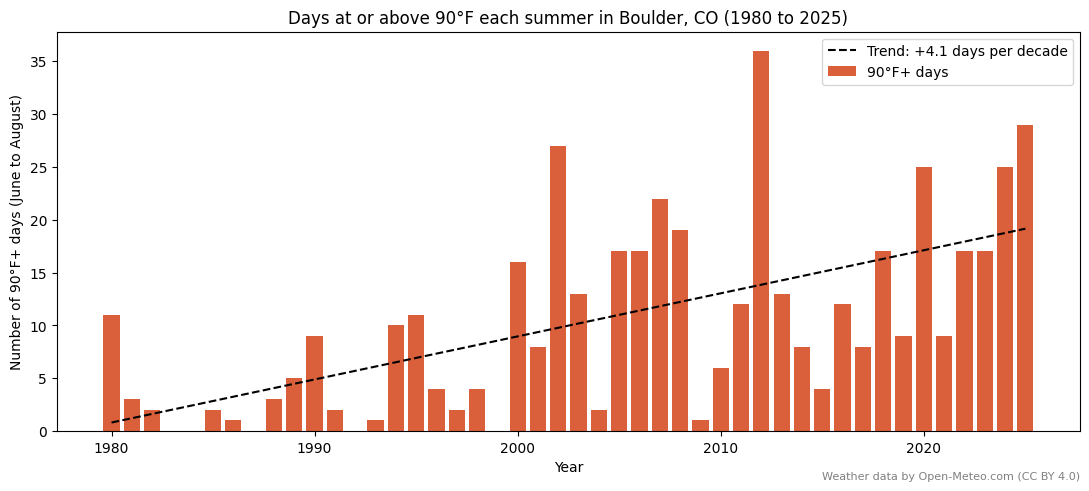

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(summers.index, summers["hot_days"], color="#d9603b", label="90°F+ days")
ax.plot(summers.index, intercept + slope * summers.index, color="black",
        linestyle="--", label=f"Trend: +{slope * 10:.1f} days per decade")
ax.set_title("Days at or above 90°F each summer in Boulder, CO (1980 to 2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of 90°F+ days (June to August)")
ax.legend()
ax.text(1, -0.12, CREDIT, transform=ax.transAxes, ha="right", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig(FIG_DIR / "hot_days_per_year.png", dpi=200)
plt.show()

*Figure 1. Boulder's number of 90°F+ summer days has risen by about 4 days per decade since 1980, with 2012 the hottest summer on record in this data.*

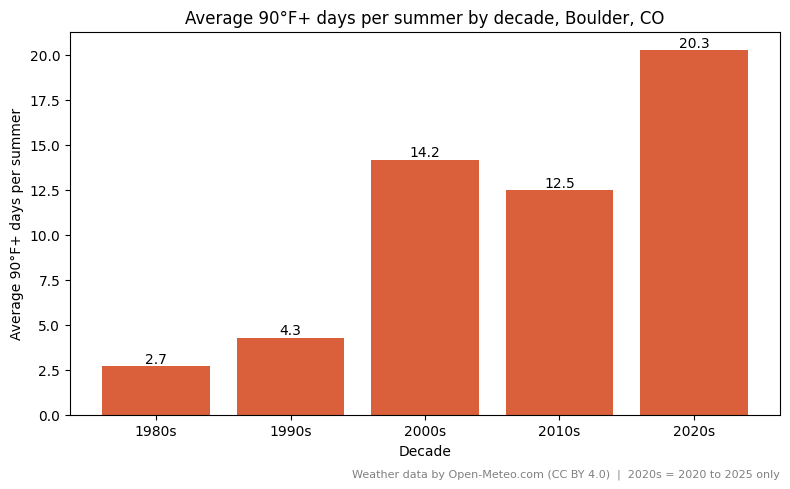

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(decades.index, decades["avg_hot_days"], color="#d9603b")
ax.bar_label(bars, fmt="%.1f")
ax.set_title("Average 90°F+ days per summer by decade, Boulder, CO")
ax.set_xlabel("Decade")
ax.set_ylabel("Average 90°F+ days per summer")
ax.text(1, -0.14, CREDIT + "  |  2020s = 2020 to 2025 only", transform=ax.transAxes,
        va="top", ha="right", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig(FIG_DIR / "hot_days_by_decade.png", dpi=200)
plt.show()

*Figure 2. Summers in the 2020s have averaged about 20 days at or above 90°F, more than seven times the 1980s average.*

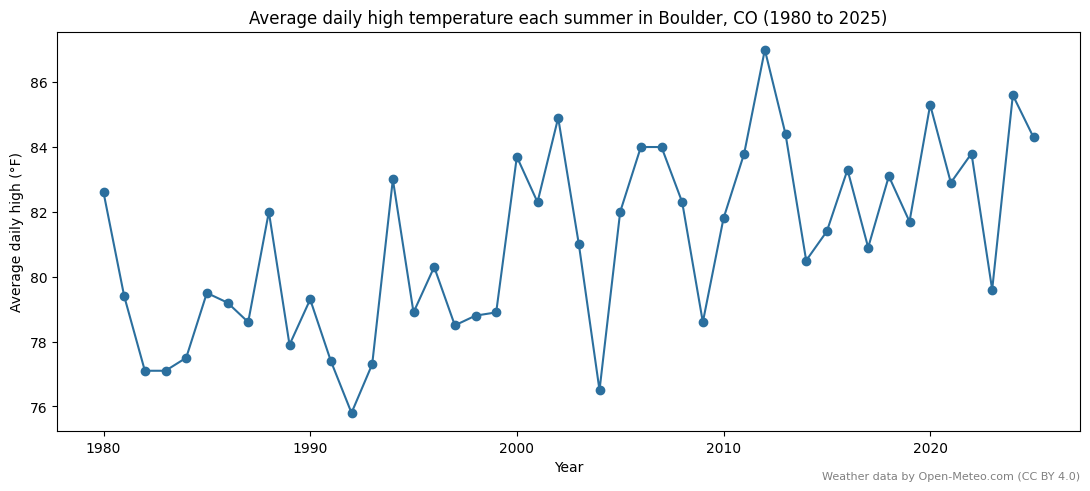

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(summers.index, summers["avg_high_f"], marker="o", color="#2b6f9e")
ax.set_title("Average daily high temperature each summer in Boulder, CO (1980 to 2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Average daily high (°F)")
ax.text(1, -0.12, CREDIT, transform=ax.transAxes, ha="right", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig(FIG_DIR / "avg_summer_high.png", dpi=200)
plt.show()

*Figure 3. Average summer highs rise and fall with the count of 90°F+ days, so hotter summers overall bring more extreme heat days.*